import required library

In [1]:
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt
import sys

print("Libraries imported successfully")
print("Python executable:", sys.executable)

Libraries imported successfully
Python executable: C:\Users\NEW GEN LAPTOP\anaconda3\python.exe


load image

In [2]:
image = cv.imread("my_image.jpg")

if image is None:
    raise FileNotFoundError("Image not found. Check the filename.")

print("Image loaded successfully")
print("Image shape:", image.shape)
print("Image data type:", image.dtype)

Image loaded successfully
Image shape: (1480, 1500, 3)
Image data type: uint8


inspect image

In [3]:
height, width, channels = image.shape

print("Image Height:", height)
print("Image Width:", width)
print("Number of channels:", channels)

print("Top-left Pixel (BGR):", image[0, 0])

center_y = height //2
center_x = width // 2

print("Center Pixel (BGR):", image[center_y, center_x])

print("Globel Minimum:", np.min(image))
print("Globel Maximum:", np.max(image))

print("Blue Channel Minimum:", np.min(image[:, :, 0]))
print("Blue Channel Maximum:", np.max(image[:, :, 0]))

print("Green Channel Minimum:", np.min(image[:, :, 1]))
print("Green Channel Maximum:", np.max(image[:, :, 1]))

print("Red Channel Minimum:", np.min(image[:, :, 2]))
print("Red Channel Maximim:", np.max(image[:, :, 2]))


Image Height: 1480
Image Width: 1500
Number of channels: 3
Top-left Pixel (BGR): [40 56 15]
Center Pixel (BGR): [148  90  38]
Globel Minimum: 0
Globel Maximum: 255
Blue Channel Minimum: 0
Blue Channel Maximum: 255
Green Channel Minimum: 5
Green Channel Maximum: 255
Red Channel Minimum: 0
Red Channel Maximim: 255


#convert the image color

In [4]:
rgb = cv.cvtColor(image, cv.COLOR_BGR2RGB)

gray = cv.cvtColor(image, cv.COLOR_BGR2GRAY)

print("Image converted from BGR to RGB")
print("Grayscale image created successfully")

Image converted from BGR to RGB
Grayscale image created successfully


#separate the color channels

In [5]:
blue, green, red = cv.split(image)

print("Blue, Green, Red channels separated successfully")

Blue, Green, Red channels separated successfully


#dispay all six images

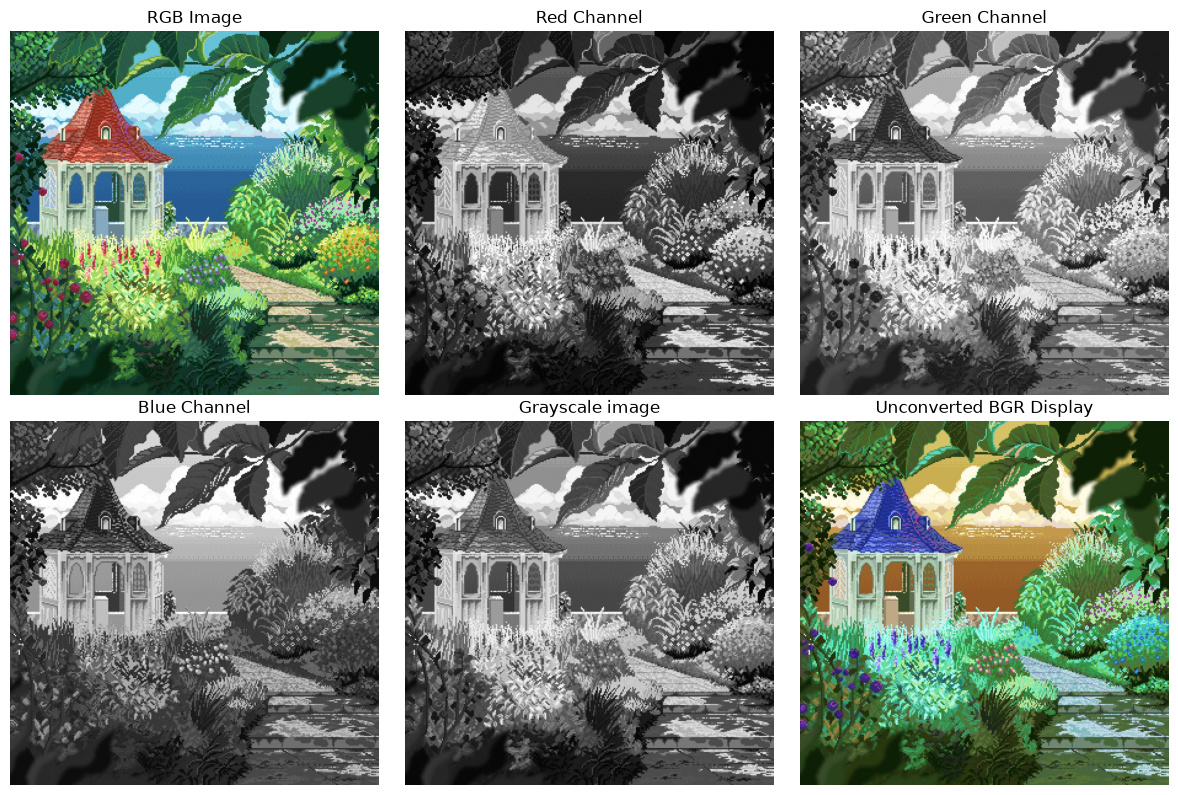

In [6]:
plt.figure(figsize=(12, 8))

plt.subplot(2, 3, 1)
plt.imshow(rgb)
plt.title("RGB Image")
plt.axis("off")

plt.subplot(2, 3, 2)
plt.imshow(red, cmap="gray")
plt.title("Red Channel")
plt.axis("off")

plt.subplot(2, 3, 3)
plt.imshow(green, cmap="gray")
plt.title("Green Channel")
plt.axis("off")

plt.subplot(2, 3, 4)
plt.imshow(blue, cmap="gray")
plt.title("Blue Channel")
plt.axis("off")

plt.subplot(2, 3, 5)
plt.imshow(gray, cmap="gray")
plt.title("Grayscale image")
plt.axis("off")

plt.subplot(2, 3, 6)
plt.imshow(image)
plt.title("Unconverted BGR Display")
plt.axis("off")

plt.tight_layout()
plt.show()

#find the center pixel HEX color

In [17]:
height, width, channels = image.shape

center_y = height // 2
center_x = width // 2

center_rgb = rgb[center_y, center_x]

red_value = int(center_rgb[0])
green_value = int(center_rgb[1])
blue_value = int(center_rgb[2])

hex_color = "#{:02x}{:02x}{:02x}".format(red_value, green_value, blue_value)

print("Center pixel RGB value:", center_rgb)
print("Center pixel HEX color:", hex_color)

Center pixel RGB value: [ 38  90 148]
Center pixel HEX color: #265a94


#crop image

In [7]:
crop = image[0:100, 0:100]

print("Crop shape:", crop.shape)

Crop shape: (100, 100, 3)


#resize image

In [8]:
resized = cv.resize(crop, (200, 200))

print("Resized image shape:", resized.shape)

Resized image shape: (200, 200, 3)


#display three image

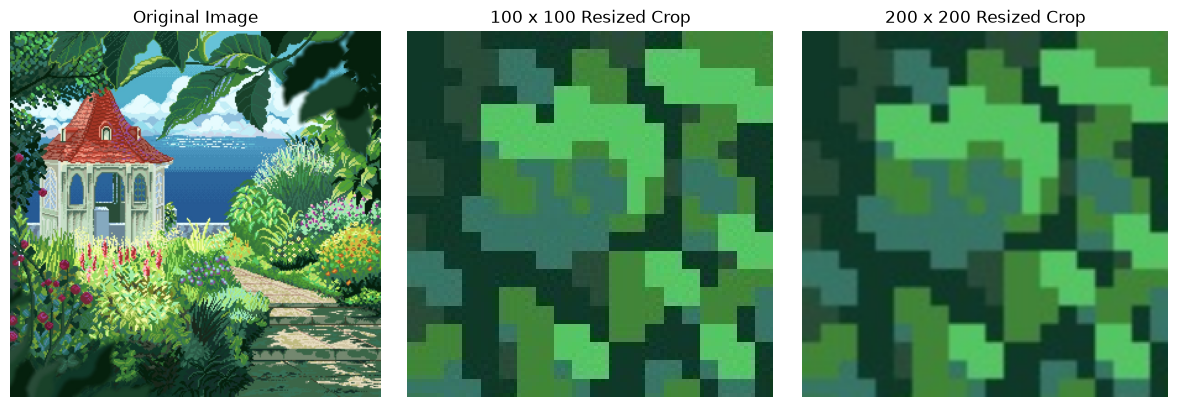

In [9]:
crop_rgb = cv.cvtColor(crop, cv.COLOR_BGR2RGB)
resized_rgb = cv.cvtColor(resized, cv.COLOR_BGR2RGB)

plt.figure(figsize=(12, 4))

plt.subplot(1,3,1)
plt.imshow(rgb)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(crop_rgb)
plt.title("100 x 100 Resized Crop")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(resized_rgb)
plt.title("200 x 200 Resized Crop")
plt.axis("off")

plt.tight_layout()
plt.show()

#save resized image

In [10]:
resized_bgr = cv.cvtColor(resized_rgb, cv.COLOR_RGB2BGR)

saved = cv.imwrite("resized_crop.png", resized_bgr)

print("Image saved successfully:", saved)

Image saved successfully: True


In [11]:
import os 
print(os.path.exists("resized_crop.png"))

True


#create histogram

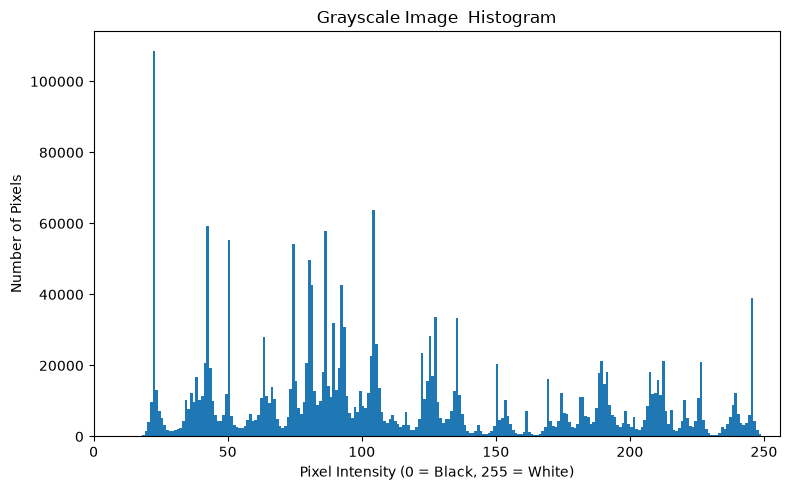

Histogram saved successfully.


In [12]:
gray_values = gray.flatten()

plt.figure(figsize=(8, 5))

plt.hist(gray_values, bins=256, range=(0, 256))

plt.title("Grayscale Image  Histogram")
plt.xlabel("Pixel Intensity (0 = Black, 255 = White)")
plt.ylabel("Number of Pixels")

plt.xlim(0, 256)
plt.tight_layout()

plt.savefig("grayscale_histogram.png")
plt.show()

print("Histogram saved successfully.")


#create gradient

In [13]:
gradient = np.arange(256, dtype=np.uint8)
gradient = np.tile(gradient, (50, 1))

gradient_1bit = (gradient // 128) * 255

gradient_2bit = np.round(gradient / 85) * 85
gradient_2bit = gradient_2bit.astype(np.uint8)

gradient_4bit = np.round(gradient / 17) * 17
gradient_4bit = gradient_4bit.astype(np.uint8)

print("Gradient created successfully")



Gradient created successfully


#count unique intensity value

In [14]:
print("8-bit unique values:", len(np.unique(gradient)))
print("1-bit unique values:", len(np.unique(gradient_1bit)))
print("2-bit unique values:", len(np.unique(gradient_2bit)))
print("4-bit unique values:", len(np.unique(gradient_4bit)))

8-bit unique values: 256
1-bit unique values: 2
2-bit unique values: 4
4-bit unique values: 16


#display all four gradient

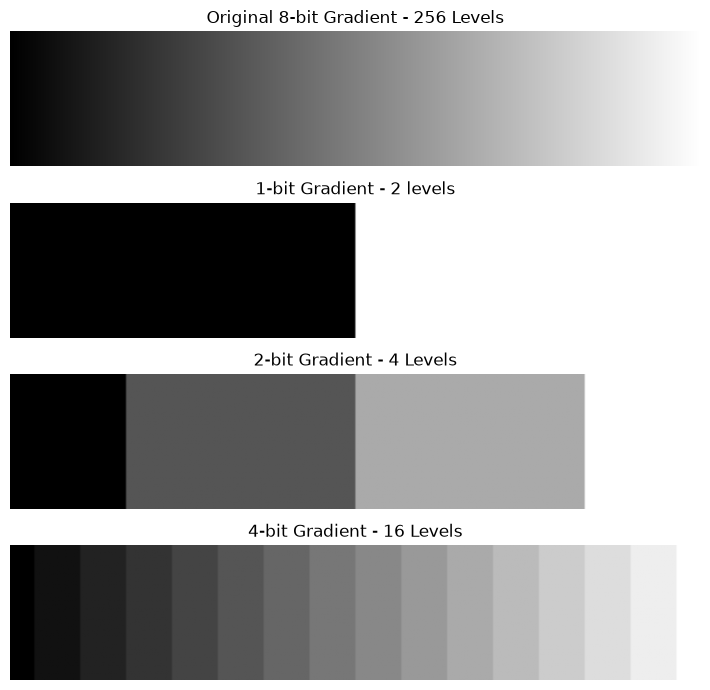

In [16]:
plt.figure(figsize=(12, 7))

plt.subplot(4, 1, 1)
plt.imshow(gradient, cmap="gray", vmin=0, vmax=255)
plt.title("Original 8-bit Gradient - 256 Levels")
plt.axis("off")

plt.subplot(4, 1, 2)
plt.imshow(gradient_1bit, cmap="gray", vmin=0, vmax=255)
plt.title("1-bit Gradient - 2 levels")
plt.axis("off")

plt.subplot(4, 1, 3)
plt.imshow(gradient_2bit, cmap="gray", vmin=0, vmax=255)
plt.title("2-bit Gradient - 4 Levels")
plt.axis("off")

plt.subplot(4, 1, 4)
plt.imshow(gradient_4bit, cmap="gray", vmin=0, vmax=255)
plt.title("4-bit Gradient - 16 Levels")
plt.axis("off")

plt.tight_layout()
plt.show()